# Работа с библиотекой Pandas

* Для визуального анализа построены столбчатая диаграмма топ-10 марок, линейный и точечный графики, а также гистограмма логарифма годового дохода.


1. Загрузите набор данных из файла **car_data.csv** по примеру с лекции



In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = Path("car_data.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Не найден файл car_data.csv. Поместите его в папку с notebook.ipynb."
    )

df = pd.read_csv(data_path)
# Убираем случайные пробелы в названиях столбцов (например, у Dealer_No).
df.columns = df.columns.str.strip()

# Преобразуем числовые поля в числа; некорректные значения станут пропусками.
for column in ["Annual Income", "Price ($)"]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

required_columns = {"Annual Income", "Company", "Model", "Price ($)", "Body Style"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"В CSV не найдены необходимые столбцы: {sorted(missing_columns)}")

print(f"Размер набора данных: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())
df.info()

Размер набора данных: 5001 строк, 17 столбцов


,Unnamed: 0,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
0,0,C_CND_000001,1/2/2022,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,DoubleÂ Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown
1,1,C_CND_000002,1/2/2022,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,DoubleÂ Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora
2,2,C_CND_000003,1/2/2022,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville
3,3,C_CND_000004,1/2/2022,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco
4,4,C_CND_000005,1/2/2022,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,DoubleÂ Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5001 entries, 0 to 5000
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unnamed: 0     5001 non-null   int64 
 1   Car_id         5001 non-null   object
 2   Date           5001 non-null   object
 3   Customer Name  5001 non-null   object
 4   Gender         5001 non-null   object
 5   Annual Income  5001 non-null   int64 
 6   Dealer_Name    4929 non-null   object
 7   Company        4929 non-null   object
 8   Model          5001 non-null   object
 9   Engine         5001 non-null   object
 10  Transmission   5001 non-null   object
 11  Color          5001 non-null   object
 12  Price ($)      5001 non-null   int64 
 13  Dealer_No      5001 non-null   object
 14  Body Style     5001 non-null   object
 15  Phone          5001 non-null   int64 
 16  Dealer_Region  5001 non-null   object
dtypes: int64(4), object(13)
memory usage: 664.3+ KB


2. Проведите анализ пропусков в данных. Удалите строки или столбцы, содержащие пропуски.

In [ ]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
display(missing_by_column.rename("Количество пропусков").to_frame())
print(f"Всего пропущенных значений: {int(df.isna().sum().sum())}")

rows_before, columns_before = df.shape
# Удаляем полностью пустые столбцы, затем строки, в которых остались пропуски.
df = df.dropna(axis=1, how="all")
df = df.dropna(axis=0, how="any").copy()

print(f"Строк до очистки: {rows_before}; после очистки: {len(df)}")
print(f"Столбцов до очистки: {columns_before}; после удаления пустых столбцов: {df.shape[1]}")
print(f"Осталось пропусков: {int(df.isna().sum().sum())}")
if df.empty:
    raise ValueError("После удаления строк с пропусками набор данных оказался пустым.")

,Количество пропусков
Company,72
Dealer_Name,72
Unnamed: 0,0
Car_id,0
Date,0
Gender,0
Customer Name,0
Annual Income,0
Model,0
Engine,0


Всего пропущенных значений: 144
Строк до очистки: 5001; после очистки: 4929
Столбцов до очистки: 17; после удаления пустых столбцов: 17
Осталось пропусков: 0


3. Вычислите средний доход клиентов, купивших автомобиль марки Toyota Camry.

In [ ]:
toyota_camry = df[
    df["Company"].astype(str).str.strip().str.casefold().eq("toyota")
    & df["Model"].astype(str).str.contains("camry", case=False, na=False)
]

if toyota_camry.empty:
    print("В наборе данных не найдено автомобилей Toyota Camry.")
else:
    mean_income = toyota_camry["Annual Income"].mean()
    print(f"Количество покупок Toyota Camry: {len(toyota_camry)}")
    print(f"Средний годовой доход покупателей: {mean_income:,.2f}")
    display(toyota_camry[["Company", "Model", "Annual Income"]].head())

Количество покупок Toyota Camry: 32
Средний годовой доход покупателей: 776,609.38


,Company,Model,Annual Income
224,Toyota,Camry,2180000
271,Toyota,Camry,850000
311,Toyota,Camry,1350000
408,Toyota,Camry,13500
580,Toyota,Camry,805000


4. Найдите топ 10 самых дорогих марок автомобилей за представленный период времени.


,Средняя стоимость ($)
Company,
Cadillac,41124.325203
Saab,40941.048780
Lincoln,32987.953271
Lexus,32930.897436
Buick,31560.687500
Oldsmobile,31387.188034
Plymouth,30604.331169
Saturn,30531.367188
Toyota,30415.163717


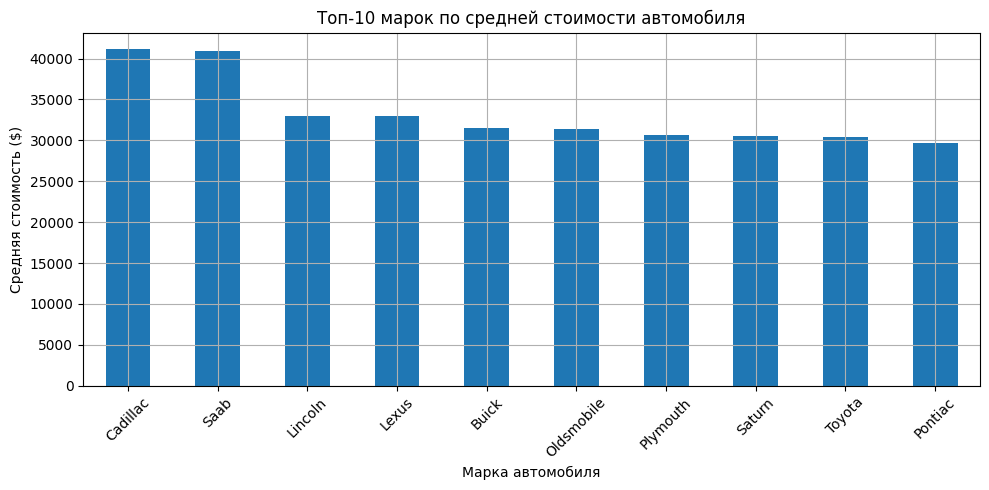

In [ ]:
mean_price_by_company = (
    df.groupby("Company")["Price ($)"].mean().sort_values(ascending=False)
)
top_10_brands = mean_price_by_company.head(10).rename("Средняя стоимость ($)").to_frame()
display(top_10_brands)

ax = top_10_brands["Средняя стоимость ($)"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Топ-10 марок по средней стоимости автомобиля",
    xlabel="Марка автомобиля",
    ylabel="Средняя стоимость ($)",
    grid=True,
)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

5. Найдите среднюю стоимость автомобилей по типам кузова (Body Style), используя метод groupby.

,Средняя стоимость ($)
Body Style,
Passenger,29845.254130
Sedan,29698.673056
Hardtop,29575.564677
Hatchback,27377.561126
SUV,26729.765799


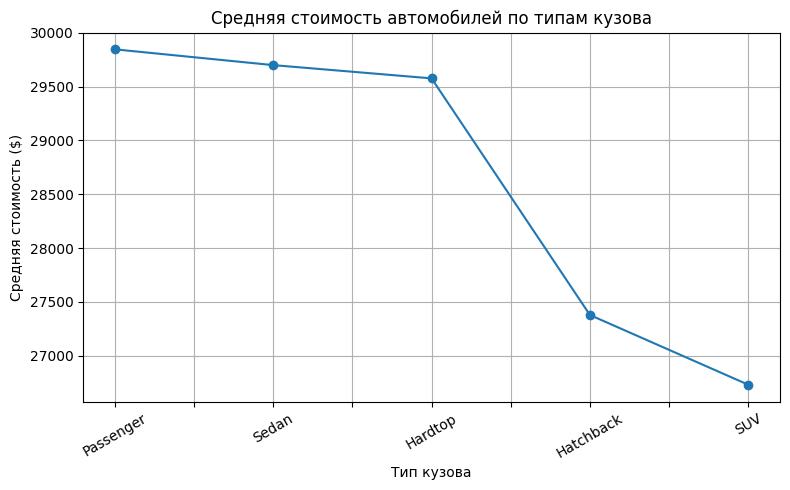

In [ ]:
mean_price_by_body_style = (
    df.groupby("Body Style")["Price ($)"].mean().sort_values(ascending=False)
)
display(mean_price_by_body_style.rename("Средняя стоимость ($)").to_frame())

ax = mean_price_by_body_style.plot(
    kind="line",
    marker="o",
    figsize=(8, 5),
    title="Средняя стоимость автомобилей по типам кузова",
    xlabel="Тип кузова",
    ylabel="Средняя стоимость ($)",
    grid=True,
)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

6. Какие автомобили приобрели 10 клиентов с самым высоким доходом?

,Customer Name,Annual Income,Company,Model,Price ($),Body Style
0,Yaakov,6240000,Chrysler,Concorde,42000,Hardtop
1,Athena,5800000,Cadillac,Eldorado,13000,Passenger
2,Francesca,5770000,Volvo,C70,17000,Hatchback
3,Fatou,5600000,Nissan,Pathfinder,21000,Hatchback
4,Malka,5525000,Volvo,S40,17500,Sedan
5,Mila,5510000,Chevrolet,Corvette,26000,SUV
6,Judah,5300000,Porsche,Carrera Cabrio,32000,Passenger
7,Emily,5110000,Volkswagen,GTI,20000,SUV
8,Aria,4900000,BMW,528i,25000,SUV
9,Jazmin,4802500,Ford,Ranger,25251,Hardtop


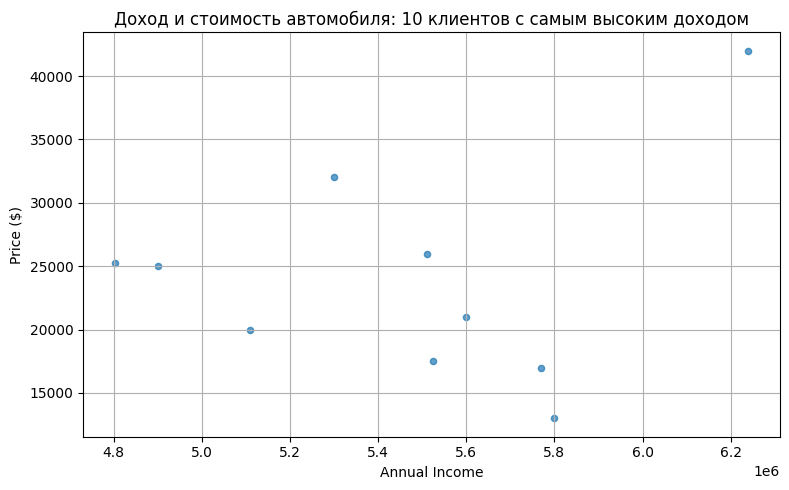

In [6]:
# Выбираем 10 записей с наибольшим годовым доходом клиентов.
top_10_high_income = df.nlargest(10, "Annual Income")
columns_to_show = [
    column
    for column in ["Customer Name", "Annual Income", "Company", "Model", "Price ($)", "Body Style"]
    if column in df.columns
]
display(top_10_high_income[columns_to_show].reset_index(drop=True))

# Точечный график: годовой доход и стоимость приобретённого автомобиля
# у 10 клиентов с наибольшим доходом.
ax = top_10_high_income.plot(
    kind="scatter",
    x="Annual Income",
    y="Price ($)",
    figsize=(8, 5),
    title="Доход и стоимость автомобиля: 10 клиентов с самым высоким доходом",
    grid=True,
    alpha=0.7,
)
plt.tight_layout()
plt.show()

7. Какие автомобили приобрели 10 клиентов с самым низким доходом?


In [ ]:
bottom_10_low_income = df.nsmallest(10, "Annual Income")
columns_to_show = [
    column
    for column in ["Customer Name", "Annual Income", "Company", "Model", "Price ($)", "Body Style"]
    if column in df.columns
]
display(bottom_10_low_income[columns_to_show].reset_index(drop=True))

,Customer Name,Annual Income,Company,Model,Price ($),Body Style
0,Geraldine,13500,Ford,Expedition,26000,SUV
1,Giselle,13500,Toyota,Celica,14000,SUV
2,Graham,13500,Mitsubishi,Galant,42000,Passenger
3,Grayson,13500,Ford,Escort,15000,Passenger
4,Gregory,13500,Acura,RL,31000,SUV
5,Amar'E,13500,Nissan,Pathfinder,46000,Hardtop
6,Harrison,13500,BMW,323i,15000,Hatchback
7,Adrianna,13500,Toyota,4Runner,25000,Sedan
8,Sloane,13500,Chrysler,LHS,41000,Hatchback
9,Haley,13500,Volvo,S40,42000,Sedan


8. Создайте новый столбец, значения которого равны логарифму от величины дохода клиентов.


,Annual Income,Log Annual Income
0,13500,9.510445
1,1480000,14.207553
2,1035000,13.849912
3,13500,9.510445
4,1465000,14.197366


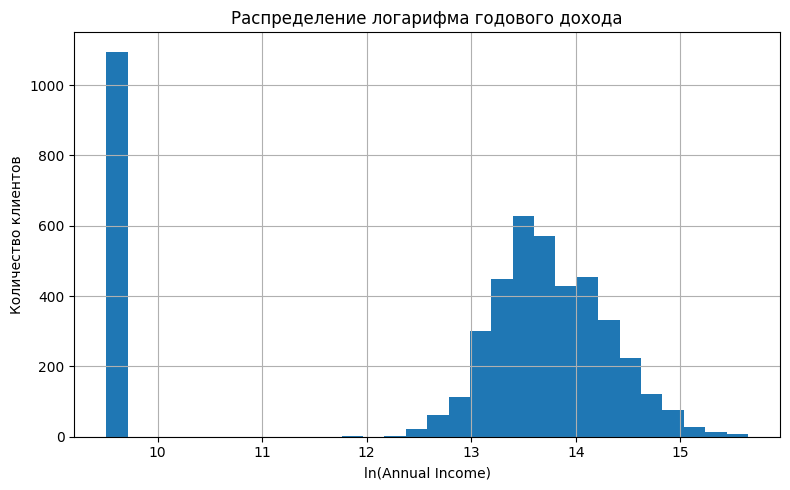

In [ ]:
# Натуральный логарифм дохода. Для нулевых или отрицательных значений логарифм
# не определён, поэтому вместо таких значений записывается NaN.
df["Log Annual Income"] = np.log(df["Annual Income"].where(df["Annual Income"] > 0))
display(df[["Annual Income", "Log Annual Income"]].head())

ax = df["Log Annual Income"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 5),
    title="Распределение логарифма годового дохода",
    xlabel="ln(Annual Income)",
    ylabel="Количество клиентов",
    grid=True,
)
plt.tight_layout()
plt.show()